# Convolutional Neural Networks: Classifying Satellite Images

Last time we trained an MLP on MNIST. Today we build a **convolutional neural network (CNN)** and train it on real satellite images from four classes: cloudy, desert, green area and water.

1. The data
2. Convolutions and the model
3. Training
4. Evaluation

> **Before you start:** make sure you're on a GPU: *Runtime → Change runtime type → T4 GPU*.

In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cpu":
    print("⚠️ No GPU found. Everything still works, just slower. "
          "In Colab: Runtime → Change runtime type → T4 GPU")

device: cpu
⚠️ No GPU found. Everything still works, just slower. In Colab: Runtime → Change runtime type → T4 GPU


## 1. The data

The dataset is hosted on Kaggle, and `kagglehub` (preinstalled on Colab) downloads it. Just run this cell.

In [3]:
CLASSES = {"cloudy", "desert", "green_area", "water"}
BACKUP_URL = ""   # direct link to a zip of the data, only used if the Kaggle download fails

def find_data_dir(path):
    """Return the folder that contains the four class folders."""
    for root, dirs, _ in os.walk(path):
        if CLASSES <= set(dirs):
            return root
    raise FileNotFoundError(f"No class folders found in {path}")

try:
    import kagglehub
    path = kagglehub.dataset_download("mahmoudreda55/satellite-image-classification")
except Exception as e:
    print("Kaggle download failed, using the backup link:", e)
    import urllib.request, zipfile
    urllib.request.urlretrieve(BACKUP_URL, "satellite.zip")
    zipfile.ZipFile("satellite.zip").extractall("satellite_data")
    path = "satellite_data"

DATA_DIR = find_data_dir(path)
print(DATA_DIR)

/opt/miniconda3/envs/SSMs/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 21.8M/21.8M [00:04<00:00, 5.39MB/s]

Extracting files...


/Users/nadezhdailieva/.cache/kagglehub/datasets/mahmoudreda55/satellite-image-classification/versions/1/data


### Know your data

Before training anything, look at the data: how many images per class, and what do they look like?

In [4]:
from PIL import Image

class_names = sorted(os.listdir(DATA_DIR))
for c in class_names:
    files = os.listdir(os.path.join(DATA_DIR, c))
    sizes = {Image.open(os.path.join(DATA_DIR, c, f)).size for f in files}
    print(f"{c:12s} {len(files):5d} images, sizes: {sizes}")

cloudy        1500 images, sizes: {(256, 256)}
desert        1131 images, sizes: {(256, 256)}
green_area    1500 images, sizes: {(64, 64)}
water         1500 images, sizes: {(64, 64)}


Two things to notice:

- The classes are slightly imbalanced (fewer desert images).
- Cloudy and desert images are 256×256, while green area and water are 64×64. We resize everything to 64×64, but this is a real quirk of the dataset: a model could partly tell the classes apart by image sharpness rather than content. Keep things like this in mind when a dataset seems "too easy".

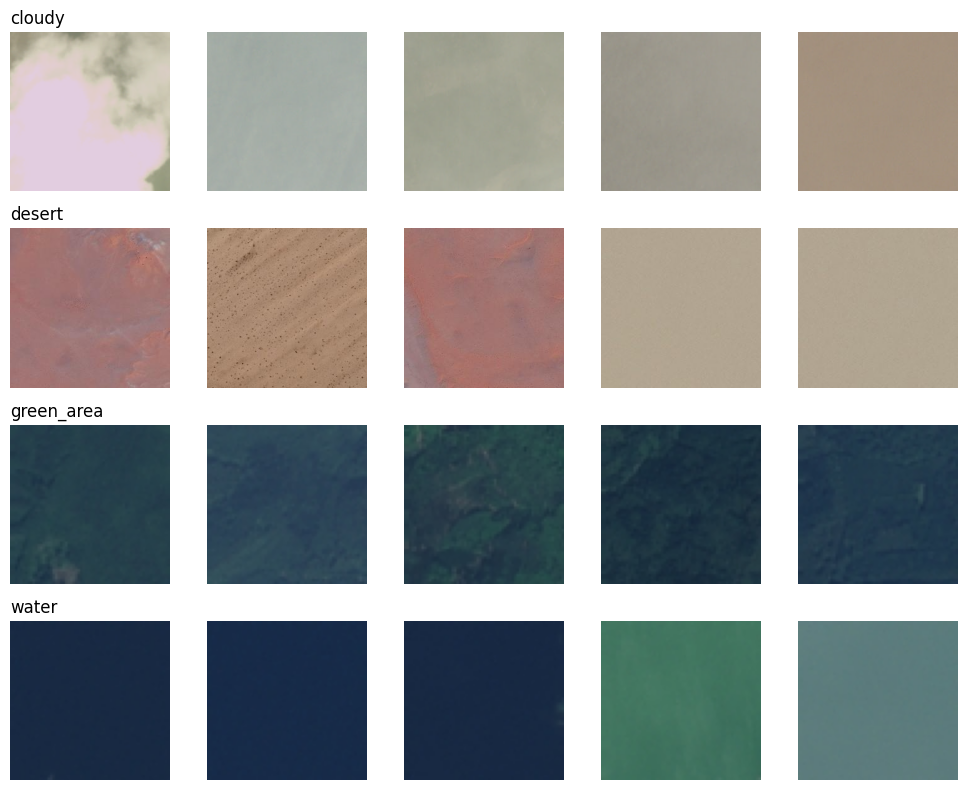

In [5]:
fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for row, c in zip(axes, class_names):
    files = sorted(os.listdir(os.path.join(DATA_DIR, c)))[:5]
    for ax, f in zip(row, files):
        ax.imshow(Image.open(os.path.join(DATA_DIR, c, f)).convert("RGB"))
        ax.axis("off")
    row[0].set_title(c, loc="left")
plt.tight_layout()
plt.show()

### Transforms

Every image goes through a pipeline of transforms when it's loaded:

- **Resize** to 64×64. Images in a batch must all have the same shape.
- **ToImage + ToDtype**: convert to a float tensor `[3, 64, 64]` with values in [0, 1].
- **Normalize**: shift values to roughly [-1, 1].

For training we also add **data augmentation**: random horizontal and vertical flips. A flipped satellite image is still the same class, so the model gets "new" examples for free, which helps against overfitting. We only augment the training data; validation and test images are evaluated as they are.

In [6]:
from torchvision.transforms import v2 as transforms

train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

### Loading and splitting

`ImageFolder` expects one subfolder per class and labels each image by its folder name. We split the data three ways:

- **train** (70%): the model learns from these
- **validation** (15%): we check progress during training and pick the best epoch
- **test** (15%): used only once, at the very end, for an honest final score

In [7]:
from torchvision.datasets import ImageFolder
from torch.utils.data import random_split

dataset = ImageFolder(DATA_DIR)     # no transform yet, see below
print(dataset.classes)
print(len(dataset), "images")

train_split, val_split, test_split = random_split(
    dataset, [0.7, 0.15, 0.15], generator=torch.Generator().manual_seed(42)
)
print(len(train_split), len(val_split), len(test_split))

['cloudy', 'desert', 'green_area', 'water']
5631 images
3942 845 844


### Writing your own Dataset

There's a catch: all three splits share the same underlying `ImageFolder`, so they would all get the same transform. We want flips for the training set only.

The fix is a small custom `Dataset`. A PyTorch dataset only needs two methods:

- `__len__`: how many samples there are
- `__getitem__(idx)`: return sample number `idx`

This is the same pattern you'd use to load any data of your own (CSV files, medical scans, ...). Ours wraps a split and applies a transform to each image:

In [8]:
from torch.utils.data import Dataset

class TransformDataset(Dataset):
    def __init__(self, base_dataset, transform):
        self.base_dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, label = self.base_dataset[idx]
        return self.transform(image), label

train_dataset = TransformDataset(train_split, train_transform)
val_dataset = TransformDataset(val_split, eval_transform)
test_dataset = TransformDataset(test_split, eval_transform)

image, label = train_dataset[0]
print(image.shape, dataset.classes[label])

torch.Size([3, 64, 64]) desert


In [9]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64)
test_loader = DataLoader(test_dataset, batch_size=64)

images, labels = next(iter(train_loader))
print(images.shape)   # [batch, channels, height, width]

torch.Size([32, 3, 64, 64])


Let's look at a batch the way the model sees it. Matplotlib wants images as `[height, width, channels]`, but PyTorch stores them as `[channels, height, width]`; `permute` reorders the dimensions. We also undo the normalization so the colours look right.

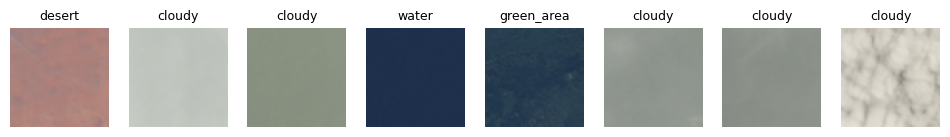

In [10]:
def show(img):
    img = img.permute(1, 2, 0)    # [3, 64, 64] -> [64, 64, 3]
    img = img * 0.5 + 0.5         # undo Normalize: [-1, 1] -> [0, 1]
    plt.imshow(img.clamp(0, 1))
    plt.axis("off")

plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    show(images[i])
    plt.title(dataset.classes[labels[i]], fontsize=9)
plt.show()

## 2. Convolutions

An MLP connects every input pixel to every neuron. For a 64×64 colour image that's 12,288 inputs per neuron, and the network has no idea which pixels are neighbours.

A **convolution** instead slides a small filter (say 3×3) over the image and computes a weighted sum of the pixels under it at every position. The same filter is reused everywhere, so a pattern such as an edge or a texture is detected wherever it appears, using only a handful of weights.

Here are two hand-made filters: one responds to vertical edges, the other (the same filter, transposed) to horizontal edges.

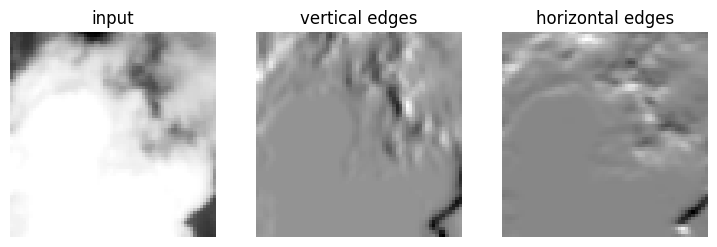

In [11]:
# dataset[0] is the first cloudy image; average the RGB channels -> grayscale [64, 64]
img = eval_transform(dataset[0][0]).mean(dim=0)

vertical = torch.tensor([[-1., 0., 1.],
                         [-2., 0., 2.],
                         [-1., 0., 1.]])
horizontal = vertical.T

# F.conv2d expects the input as [batch, channels, H, W] and the filter as [out_ch, in_ch, kH, kW]
x = img.reshape(1, 1, 64, 64)
v_edges = F.conv2d(x, vertical.reshape(1, 1, 3, 3))
h_edges = F.conv2d(x, horizontal.reshape(1, 1, 3, 3))

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, im, title in zip(axes, [img, v_edges, h_edges], ["input", "vertical edges", "horizontal edges"]):
    ax.imshow(im.squeeze(), cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

In a CNN we don't design the filters by hand: `nn.Conv2d` **learns** them during training. Its main arguments:

- `in_channels`: channels of the input (3 for RGB)
- `out_channels`: how many filters to learn. Each filter produces one output channel, a "feature map".
- `kernel_size`: the filter size, e.g. 3 for 3×3
- `padding`: a border of zeros around the input, so the output keeps the input's size

In [12]:
conv = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
print(conv.weight.shape)    # [16 filters, 3 input channels, 3, 3]

out = conv(images)
print(images.shape, "->", out.shape)

torch.Size([16, 3, 3, 3])
torch.Size([32, 3, 64, 64]) -> torch.Size([32, 16, 64, 64])


The output size of a convolution is `(input + 2·padding − kernel) / stride + 1`. With `kernel_size=3`, `padding=1` and the default `stride=1`: (64 + 2 − 3) / 1 + 1 = 64, so the size stays the same.

**Max pooling** keeps the largest value in every 2×2 block, halving the height and width. This cuts computation and makes the network less sensitive to small shifts.

In [13]:
pool = nn.MaxPool2d(2)
print(out.shape, "->", pool(out).shape)

torch.Size([32, 16, 64, 64]) -> torch.Size([32, 16, 32, 32])


### 🖐 Your turn: plan the network

Our CNN will be:

```
Conv2d(3 → 16, kernel 3, padding 1) → ReLU → MaxPool2d(2)
Conv2d(16 → 32, kernel 3, padding 1) → ReLU → MaxPool2d(2)
Flatten
Linear(? → 64) → ReLU
Linear(64 → 4)
```

Starting from a `[3, 64, 64]` image, what is the shape after each layer? How many inputs does the first `Linear` layer need?

In [14]:
in_features = ...   # your answer

<details>
<summary>Solution</summary>

`[3, 64, 64]` → conv → `[16, 64, 64]` → pool → `[16, 32, 32]` → conv → `[32, 32, 32]` → pool → `[32, 16, 16]` → flatten → 32 · 16 · 16 = **8192**
</details>

### The model

Same structure as the MLP: layers in `__init__`, data flow in `forward`. `nn.Sequential` runs a list of layers in order, which lets us group them into two blocks: `features` (convolutions that detect patterns) and `classifier` (turns those patterns into class scores).

In [15]:
class SatelliteCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

Let's check the answer by sending a fake image through the network one layer at a time. This is a handy trick whenever you hit a shape error.

In [16]:
model = SatelliteCNN().to(device)

x = torch.randn(1, 3, 64, 64).to(device)
for layer in list(model.features) + list(model.classifier):
    x = layer(x)
    print(f"{layer.__class__.__name__:10s} {tuple(x.shape)}")

Conv2d     (1, 16, 64, 64)
ReLU       (1, 16, 64, 64)
MaxPool2d  (1, 16, 32, 32)
Conv2d     (1, 32, 32, 32)
ReLU       (1, 32, 32, 32)
MaxPool2d  (1, 32, 16, 16)
Flatten    (1, 8192)
Linear     (1, 64)
ReLU       (1, 64)
Linear     (1, 4)


In [17]:
def count_params(m):
    return sum(p.numel() for p in m.parameters())

print(f"whole CNN:   {count_params(model):,} parameters")
print(f"conv layers: {count_params(model.features):,}")
print(f"first layer of an MLP on raw pixels (12288 -> 128): {count_params(nn.Linear(3 * 64 * 64, 128)):,}")

whole CNN:   529,700 parameters
conv layers: 5,088
first layer of an MLP on raw pixels (12288 -> 128): 1,572,992


The conv layers need fewer than 5,000 weights; most of the CNN's parameters sit in its first `Linear` layer. An MLP working on raw pixels would need 1.5 million weights in its first layer alone.

## 3. Training

Training works exactly like in the last notebook; only the model and the data are different.

### 🖐 Your turn: fill in the training step

Complete the five missing lines inside the loop. Look back at notebook 1 if you need to.

In [18]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        # TODO: forward pass
        # TODO: compute the loss
        # TODO: zero the gradients
        # TODO: backward pass
        # TODO: update the weights

        total_loss += loss.item()
    return total_loss / len(loader)

**Solution** (try it yourself first!)

In [19]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)           # forward
        loss = loss_fn(outputs, labels)   # loss
        optimizer.zero_grad()             # zero old gradients
        loss.backward()                   # backward
        optimizer.step()                  # update the weights

        total_loss += loss.item()
    return total_loss / len(loader)

In [20]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

`train` runs the epochs. After each one it measures validation accuracy and, whenever it's the best so far, saves the model's weights (its `state_dict`) to a file. If the model gets worse in later epochs, we still have the best version.

In [21]:
def train(model, train_loader, val_loader, loss_fn, optimizer, num_epochs):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_acc = 0.0
    for epoch in range(num_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), "best_model.pth")

        print(f"epoch {epoch + 1:2d}: train loss {train_loss:.3f} | "
              f"val loss {val_loss:.3f} | val acc {val_acc:.1%}")
    return history

In [22]:
model = SatelliteCNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history = train(model, train_loader, val_loader, loss_fn, optimizer, num_epochs=10)

epoch  1: train loss 0.531 | val loss 0.397 | val acc 81.2%
epoch  2: train loss 0.318 | val loss 0.355 | val acc 81.7%
epoch  3: train loss 0.271 | val loss 0.210 | val acc 91.2%
epoch  4: train loss 0.232 | val loss 0.228 | val acc 91.4%
epoch  5: train loss 0.214 | val loss 0.224 | val acc 89.1%
epoch  6: train loss 0.222 | val loss 0.179 | val acc 93.7%
epoch  7: train loss 0.198 | val loss 0.158 | val acc 93.0%
epoch  8: train loss 0.197 | val loss 0.208 | val acc 91.0%
epoch  9: train loss 0.182 | val loss 0.211 | val acc 92.7%
epoch 10: train loss 0.183 | val loss 0.142 | val acc 93.7%


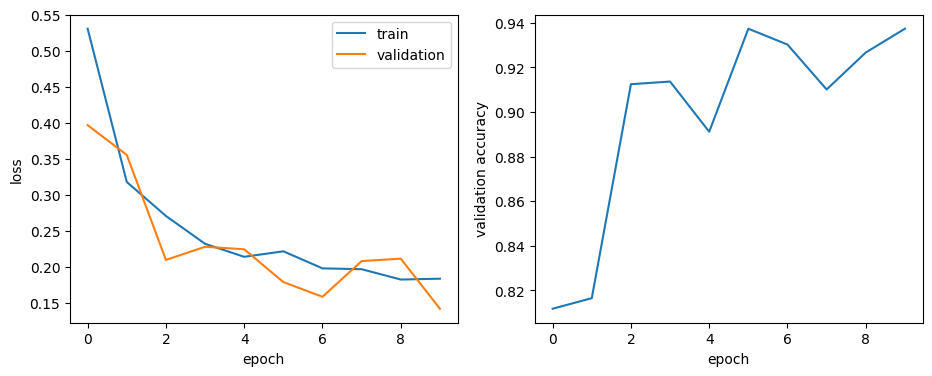

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="validation")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()
axes[1].plot(history["val_acc"])
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation accuracy")
plt.show()

How to read these curves:

- Both losses going down: the model is learning.
- Training loss still going down while validation loss goes **up**: the model is **overfitting**. It's memorizing the training images instead of learning patterns that generalize. This is where the saved best checkpoint pays off.

## 4. Evaluation

Load the best weights and score the model on the test set, which it has never seen.

In [26]:
model.load_state_dict(torch.load("best_model.pth"))
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
print(f"test accuracy: {test_acc:.1%}")

test accuracy: 93.5%


A single accuracy number can hide problems, so let's also check each class. First we collect all test predictions:

In [27]:
all_images, all_labels, all_preds = [], [], []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        preds = model(images.to(device)).argmax(dim=1).cpu()
        all_images.append(images)
        all_labels.append(labels)
        all_preds.append(preds)

# torch.cat joins the list of batches into one tensor
all_images = torch.cat(all_images)
all_labels = torch.cat(all_labels)
all_preds = torch.cat(all_preds)

for i, c in enumerate(dataset.classes):
    mask = all_labels == i
    acc = (all_preds[mask] == i).float().mean()
    print(f"{c:12s} {acc:.1%}")

cloudy       97.4%
desert       94.8%
green_area   92.4%
water        89.5%


And look at the mistakes:

55 of 844 test images misclassified


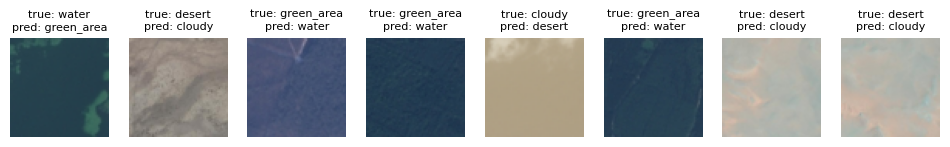

In [28]:
wrong = (all_preds != all_labels).nonzero().flatten()
print(len(wrong), "of", len(all_labels), "test images misclassified")

plt.figure(figsize=(12, 3))
for n, i in enumerate(wrong[:8]):
    plt.subplot(1, 8, n + 1)
    show(all_images[i])
    plt.title(f"true: {dataset.classes[all_labels[i]]}\npred: {dataset.classes[all_preds[i]]}", fontsize=8)
plt.show()

## 🖐 Your turn (optional)

**Exercise 3.** Add `nn.BatchNorm2d(16)` after the first `Conv2d` and `nn.BatchNorm2d(32)` after the second, and `nn.Dropout(0.5)` before the last `Linear`. Does validation accuracy change?

**Exercise 4.** Use `eval_transform` for the training set too (no augmentation). Compare the training and validation curves with the ones above.

<details>
<summary>Hints</summary>

- BatchNorm normalizes each channel over the batch, which often makes training faster and more stable. Dropout randomly switches off neurons during training, and this is exactly why `model.train()` and `model.eval()` matter: dropout must be turned off for evaluation.
- Without augmentation, expect a bigger gap between training and validation loss: more overfitting.
</details>

## Recap

- `Conv2d` learns small filters that slide over the image; `MaxPool2d` shrinks the feature maps.
- A custom `Dataset` only needs `__len__` and `__getitem__`.
- Train / validation / test: learn, pick the best model, report the final score.
- The training loop is the same as for the MLP. Only the model and the data changed.

**Going further:** in practice you rarely train a CNN from scratch. You start from a network pretrained on millions of images (e.g. `torchvision.models.resnet18(weights="DEFAULT")`) and fine-tune it on your data. This is called **transfer learning**.